## 🔍 EDA — исследовательский анализ данных

- [**1. 📁 Общая информация о датасете**](#section-1)
- [**2. 🖼️ Визуализация и анализ существующей разметки**](#section-2)
- [**3. 📊 Анализ распределения классов (брендов)**](#section-3)
- [**4. 📐 Анализ геометрических характеристик логотипов**](#section-4)
- [**5. ✅ Проверка качества и корректности разметки**](#section-5)
- [**6. 🔎 Анализ сложных случаев обнаружения логотипов**](#section-6)
- [**7. ⚖️ Сравнение обучающей, валидационной и тестовой выборок**](#section-7)
- [**8. 🧪 Исследование методов аугментации данных**](#section-8)
- [**9. 📝 Выводы и подготовка данных к обучению модели**](#section-9)

In [57]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import os
from PIL import Image
import random

In [4]:
# Корневая папка проекта BrandSight
PROJECT_DIR = Path.cwd().parent

# Папка с датасетом
DATA_DIR = PROJECT_DIR / "data"

# Папки выборок
TRAIN_DIR = DATA_DIR / "train"
VAL_DIR = DATA_DIR / "val"
TEST_DIR = DATA_DIR / "test"

# Изображения
TRAIN_IMAGES = TRAIN_DIR / "images"
VAL_IMAGES = VAL_DIR / "images"
TEST_IMAGES = TEST_DIR / "images"

# Разметка
TRAIN_LABELS = TRAIN_DIR / "labels"
VAL_LABELS = VAL_DIR / "labels"
TEST_LABELS = DATA_DIR / "test" / "labels"

In [5]:
print("Корень проекта:", PROJECT_DIR)
print("Папка с данными:", DATA_DIR)
print("Папка существует:", DATA_DIR.exists())

Корень проекта: c:\Users\Huawei\Desktop\BrandSight
Папка с данными: c:\Users\Huawei\Desktop\BrandSight\data
Папка существует: True


<a id="section-1"></a>
### 1. 📁 Общая информация о датасете

In [6]:
train_images = list(TRAIN_IMAGES.iterdir())
val_images = list(VAL_IMAGES.iterdir())
test_images = list(TEST_IMAGES.iterdir())

print("Train:", len(train_images))
print("Validation:", len(val_images))
print("Test:", len(test_images))

Train: 867
Validation: 36
Test: 53


In [7]:
total_images = len(train_images) + len(val_images) + len(test_images)

In [40]:
print(f"Количество всех изображений: {total_images}")

Количество всех изображений: 956


In [9]:
print(f"Доля тренировочных изображений: {round(100 * len(train_images) / total_images, 2)}%")
print(f"Доля валидационных изображений: {round(100 * len(val_images) / total_images, 2)}%")
print(f"Доля тестовых изображений: {round(100 * len(test_images) / total_images, 2)}%")

Доля тренировочных изображений: 90.69%
Доля валидационных изображений: 3.77%
Доля тестовых изображений: 5.54%


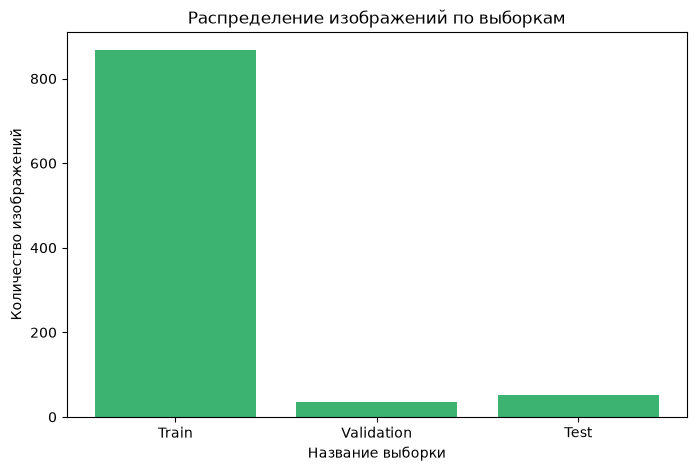

In [10]:
plt.figure(figsize=(8, 5))
plt.bar(["Train", "Validation", "Test"],
        [len(train_images), len(val_images), len(test_images)],
        color="mediumseagreen")

plt.title("Распределение изображений по выборкам")
plt.ylabel("Количество изображений")
plt.xlabel("Название выборки")
plt.show()

In [41]:
print("Разметка по Train:", len(list(TRAIN_LABELS.glob("*.txt"))))
print("Разметка по Validation:", len(list(VAL_LABELS.glob("*.txt"))))
print("Разметка по Test:", len(list(TEST_LABELS.glob("*.txt"))))

Разметка по Train: 943
Разметка по Validation: 55
Разметка по Test: 24


In [12]:
for name, images, labels in [
    ("Train", TRAIN_IMAGES, TRAIN_LABELS),
    ("Validation", VAL_IMAGES, VAL_LABELS),
    ("Test", TEST_IMAGES, TEST_LABELS)
]:
    image_names = {f.stem for f in images.iterdir() if f.is_file()}
    label_names = {f.stem for f in labels.glob("*.txt")}

    print(f"\n{name}")
    print("Разметка без изображения:", len(label_names - image_names))
    print("Изображения без разметки:", len(image_names - label_names))


Train
Разметка без изображения: 119
Изображения без разметки: 43

Validation
Разметка без изображения: 19
Изображения без разметки: 0

Test
Разметка без изображения: 1
Изображения без разметки: 30


In [49]:
data = []

for name, images, labels in [
    ("Train", TRAIN_IMAGES, TRAIN_LABELS),
    ("Validation", VAL_IMAGES, VAL_LABELS),
    ("Test", TEST_IMAGES, TEST_LABELS)
]:
    image_names = {f.stem for f in images.iterdir() if f.is_file()}
    label_names = {f.stem for f in labels.glob("*.txt")}

    data.append({
        "Выборка": name,
        "Изображения": len(image_names),
        "Файлы разметки": len(label_names),
        "Разметка без изображения": len(label_names - image_names),
        "Изображения без разметки": len(image_names - label_names),
        "Совпадающие пары": len(image_names & label_names)
    })

eda_matching_df = pd.DataFrame(data)

display(eda_matching_df)

,Выборка,Изображения,Файлы разметки,Разметка без изображения,Изображения без разметки,Совпадающие пары
0,Train,867,943,119,43,824
1,Validation,36,55,19,0,36
2,Test,53,24,1,30,23


На этом этапе выявилась одна из первых серьёзных проблем проекта: версия датасета, опубликованная на Hugging Face, не соответствует данным, описанным в статье Exposure Engine.

Вероятно, на платформу загрузили не весь датасет или часть данных не была опубликована по соображениям безопасности. Я уже связался с авторами статьи и ожидаю ответа по поводу возможности получить полную версию датасета.

Пока продолжаю EDA, поскольку выявленные несоответствия не препятствуют дальнейшему анализу. Количество файлов без соответствующих изображений и изображений без разметки не превышает 10–15% от общего объёма данных, поэтому на данном этапе это не критично.

Далее планирую изучить распределение логотипов по классам и проверить качество разметки непосредственно на изображениях. Это позволит оценить состояние датасета и выявить проблемы, которые могут повлиять на качество будущей модели.

In [52]:
for name, folder in [
    ("Train", TRAIN_DIR),
    ("Validation", VAL_DIR),
    ("Test", TEST_DIR)
]:
    size = 0

    for root, dirs, files in os.walk(folder):
        for file in files:
            path = os.path.join(root, file)
            size += os.path.getsize(path)

    print(name, round(size / (1024 ** 2), 2), "MB")

Train 122.48 MB
Validation 4.87 MB
Test 6.84 MB


In [55]:
formats = {}
sizes = {}

for folder in [TRAIN_IMAGES, VAL_IMAGES, TEST_IMAGES]:
    for file in folder.iterdir():
        img = Image.open(file)

        formats[img.format] = formats.get(img.format, 0) + 1
        sizes[img.size] = sizes.get(img.size, 0) + 1

print("Форматы:", formats)
print("Разрешения:", sizes)

Форматы: {'JPEG': 956}
Разрешения: {(1280, 720): 956}


<a id="section-2"></a>
### 2. 🖼️ Визуализация и анализ существующей разметки

Для начала посмотрю в целом на картинки, которые находятся в каждой выборке:

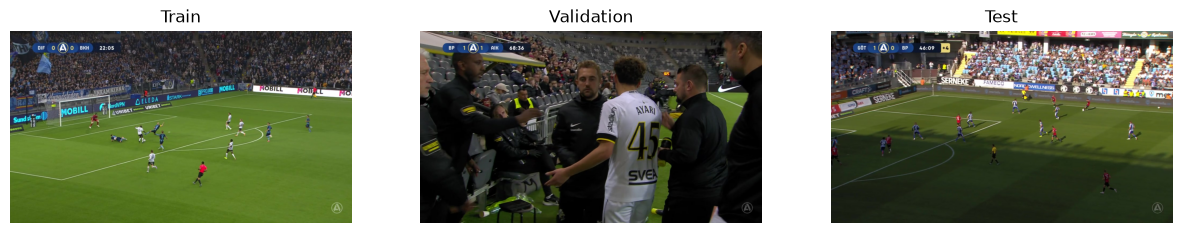

In [59]:
folders = [
    ("Train", TRAIN_IMAGES),
    ("Validation", VAL_IMAGES),
    ("Test", TEST_IMAGES)
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (name, folder) in zip(axes, folders):
    images = list(folder.glob("*.jpg"))
    file = random.choice(images)

    ax.imshow(Image.open(file))
    ax.set_title(name)
    ax.axis("off")

plt.show()

<a id="section-3"></a>
### 3. 📊 Анализ распределения классов (брендов)

<a id="section-4"></a>
### 4. 📐 Анализ геометрических характеристик логотипов

<a id="section-5"></a>
### 5. ✅ Проверка качества и корректности разметки

<a id="section-6"></a>
### 6. 🔎 Анализ сложных случаев обнаружения логотипов

<a id="section-7"></a>
### 7. ⚖️ Сравнение обучающей, валидационной и тестовой выборок

<a id="section-8"></a>
### 8. 🧪 Исследование методов аугментации данных

<a id="section-9"></a>
### 9. 📝 Выводы и подготовка данных к обучению модели